In [2]:
import pandas as pd

df = pd.read_csv(r"C:\docx\Predictive_Maintenance\data\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## EDA

In [4]:
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [5]:
print("Missing Values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("Total Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

Missing Values:


,Missing Count
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Total Missing Values: 0
Duplicate Rows: 0


Failure Counts:


Machine failure
0    9661
1     339
Name: count, dtype: int64


Failure Percentages:


Machine failure
0    96.61
1     3.39
Name: Percentage, dtype: float64

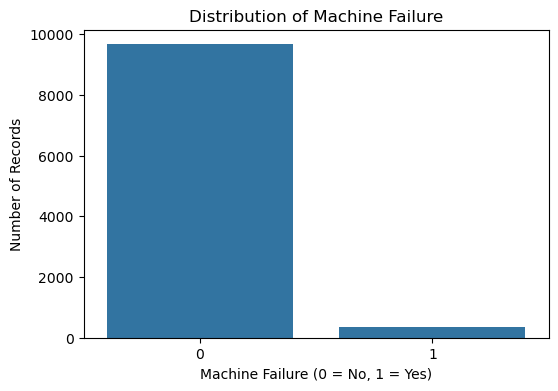

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

target = "Machine failure"

print("Failure Counts:")
display(df[target].value_counts().sort_index())

print("\nFailure Percentages:")
display(
    (df[target].value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .rename("Percentage")
)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

In [7]:
sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

failure_comparison = df.groupby(target)[sensor_cols].mean().T
failure_comparison.columns = ["No Failure", "Failure"]

display(failure_comparison.round(2))

,No Failure,Failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


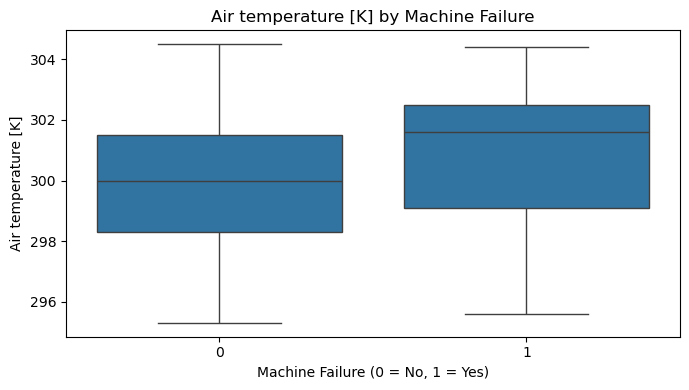

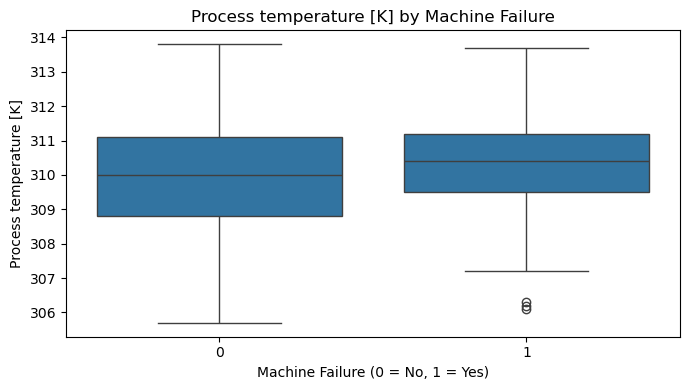

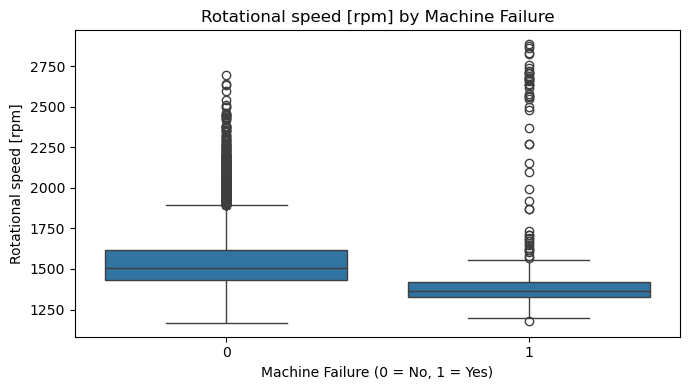

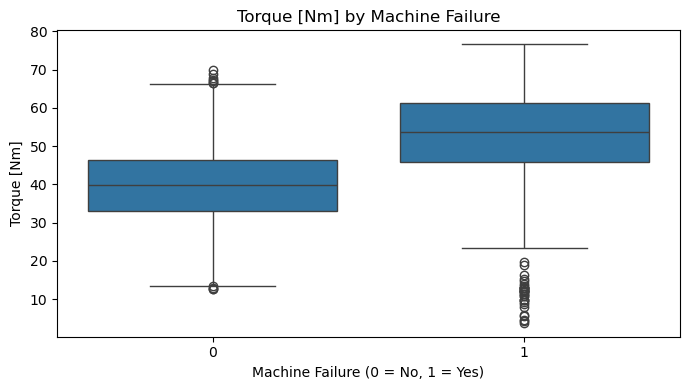

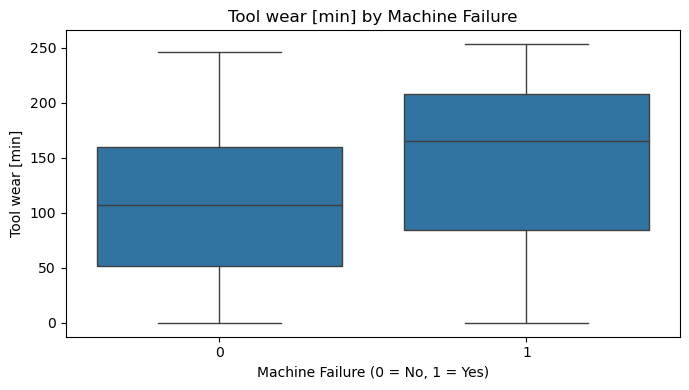

In [8]:
for col in sensor_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df, x=target, y=col)

    plt.title(f"{col} by Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()

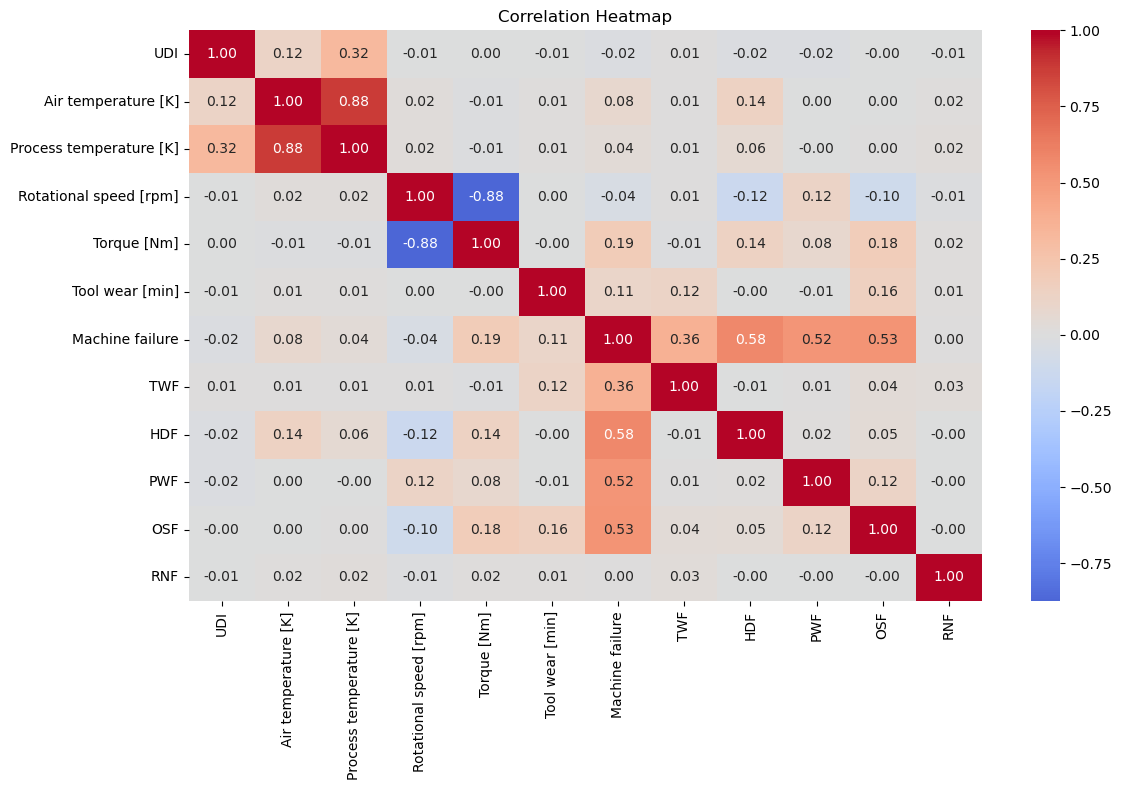

In [9]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [10]:
# Failure rate for each machine type
type_failure_rate = (
    df.groupby("Type")[target]
      .agg(["count", "sum", "mean"])
      .rename(columns={
          "count": "Total Records",
          "sum": "Failure Records",
          "mean": "Failure Rate"
      })
)

type_failure_rate["Failure Rate (%)"] = (
    type_failure_rate["Failure Rate"] * 100
)

display(type_failure_rate.round(2))

,Total Records,Failure Records,Failure Rate,Failure Rate (%)
Type,,,,
H,1003,21,0.02,2.09
L,6000,235,0.04,3.92
M,2997,83,0.03,2.77


In [11]:
failure_mode_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

display(
    df[failure_mode_cols]
    .sum()
    .sort_values(ascending=False)
    .to_frame("Number of Records")
)

,Number of Records
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19


## feature selction 

In [12]:
from sklearn.model_selection import train_test_split

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

X = df[features].copy()
y = df[target].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (10000, 6)
Target shape: (10000,)

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64
